##ЛР3. Задача классификации

[12 баллов]

## О формате сдачи (все ЛР)

🔷 **<font color='plum'>При решении используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, могут помечаться фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, могут помечаться фразами "Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Выводы подразумевают текстовый (письменный, не устный) ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

🔷 **<font color='plum'>Устная защита</font>**

    ❌❌❌ Если не пройдена устная защита по ЛР, то баллы не начисляются вовсе
    (вопросы устной защиты охватывают лекционный материал и практический материал по заданиям ЛР, список вопросов не публикуется)

Данилов Тимофей и Пивоваров Роман.

Взял [объявления о недвижимости в Португалии](https://www.kaggle.com/datasets/luvathoms/portugal-real-estate-2024) из ЛР1–2.

## Этапы

<font color='DarkOrange'>**Задание 1 [баллов: 2]:**</font>

Выберите датасет и задачу для него (классификация) - с Kaggle или UCI Machine Learning Repository (https://archive.ics.uci.edu/datasets).
Важно: используйте более новые датасеты, кол-во объектов не менее 100.
Лучше воспользоваться датасетом из предыдущих ЛР.

Выберите (или сгенерите сами) признак, который будет целевым для бинарной классификации.

Используйте LogisticRegression из sklearn. Задайте несколько параметров метода самостоятельно, поясните их назначение и причину выбора конкретных значений.
Используйте несколько метрик, чтоб оценить результаты бинарной классификации (метрики, доступные в sklearn).

### Что буду предсказывать

Разделил квартиры на два класса: от 500 тыс. € и дешевле. Порог выбрал заранее, по test его не считал. Это условная граница дорогого сегмента для этой работы.

Для прогноза взял те же восемь признаков, что в ЛР1–2: площадь, санузлы, год постройки, парковку, лифт, сертификат, округ и город. Цену оставил только в целевой переменной. Цену за м² и другие производные цены в признаки не добавлял.

Оставил квартиры с 01.07.2025, площадью 10–1000 м² и ценой от 10 тыс. до 20 млн €. Полные дубликаты удалил до разбиения. В прошлых работах удалял строки с пропусками, здесь заполняю их внутри Pipeline. Поэтому выборка больше и test новый, сравнивать его с прежним разбиением напрямую нельзя.

На test отвел 20% со стратификацией по классу. Медианы, масштабирование и кодирование категорий считаются на обучающей части каждого фолда. Test в подборе C не участвует.

Так проверяю качество на похожих объявлениях. Перенос на будущий рынок отдельно не проверял. Еще остаются возможные объявления об одной квартире: без ID объекта их нельзя надежно разделить.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, OneClassSVM
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay,
)

ROOT = Path.cwd() if (Path.cwd() / "lab1").exists() else Path.cwd().parent
SEED, THRESHOLD = (67, 500000)
NUM = ["LivingArea", "NumberOfBathrooms", "ConstructionYear", "Parking", "Elevator"]
CAT = ["EnergyCertificate", "District", "City"]
FEATURES = NUM + CAT
plt.rcParams.update({"figure.figsize": (10, 4), "figure.dpi": 110})
pd.set_option("display.max_columns", 20)
path = ROOT / "lab1/data/portugal_listinigs.csv"
raw = pd.read_csv(path, low_memory=False)
df = raw.drop_duplicates().copy()
df["PublishDate"] = pd.to_datetime(df["PublishDate"], errors="coerce")
df["Elevator"] = df["Elevator"].map({True: 1.0, False: 0.0, "True": 1.0, "False": 0.0})
df = df.loc[
    (df["Type"] == "Apartment")
    & (df["PublishDate"] >= "2025-07-01")
    & df["LivingArea"].between(10, 1000)
    & df["Price"].between(10000, 20000000)
].copy()
for col, lo, hi in [
    ("NumberOfBathrooms", 0, 10),
    ("ConstructionYear", 1900, 2026),
    ("Parking", 0, 20),
]:
    df.loc[~df[col].between(lo, hi), col] = np.nan
df["EnergyCertificate"] = df["EnergyCertificate"].replace(
    {"No Certificate": "NC", "Not available": "NC"}
)
for col in CAT:
    df[col] = df[col].astype(object).where(df[col].notna(), np.nan)
y = (df.Price >= THRESHOLD).astype(int)
train_idx, test_idx = train_test_split(
    df.index, test_size=0.2, random_state=SEED, stratify=y
)
X_train, X_test = (df.loc[train_idx, FEATURES], df.loc[test_idx, FEATURES])
y_train, y_test = (y.loc[train_idx], y.loc[test_idx])
display(
    pd.DataFrame(
        {
            "n": [len(y_train), len(y_test)],
            "expensive": [y_train.sum(), y_test.sum()],
            "expensive_share": [y_train.mean(), y_test.mean()],
        },
        index=["train", "test"],
    )
)

,n,expensive,expensive_share
train,13832,3221,0.232866
test,3458,805,0.232794


### Как обучал LogisticRegression

Модель считает вероятность класса 1 через sigmoid(wᵀx+b). При обучении минимизирует log-loss с L2-регуляризацией. C задает обратную силу регуляризации: чем он меньше, тем сильнее ограничены веса.

Поставил solver=lbfgs для гладкой задачи с L2, max_iter=3000 с запасом на сходимость и tol=1e-4 для остановки. Для редкого класса использовал class_weight=balanced. Вес класса равен n/(2·n_k), поэтому ошибка на редком классе стоит дороже. В каждом фолде веса считаются заново.

Проверил C=0.01, 0.1 и 1 на трех стратифицированных фолдах train. Выбираю по balanced accuracy, чтобы оба класса влияли на оценку поровну. В Pipeline заполняю пропуски, логарифмирую площадь, масштабирую числовые признаки и кодирую категории через One-Hot. Категории с частотой меньше 30 объединяю.

На test считаю accuracy, balanced accuracy, precision, recall, F1, ROC AUC и AP. Последние две метрики считаю по score, не по готовым меткам. AP суммирует precision с весами прироста recall, это не площадь PR по трапециям. Для сравнения добавил модель, которая всегда выбирает частый класс.

У LogisticRegression оставил порог 0.5. После взвешивания классов вероятности могут быть некалиброваны, отдельно калибровку не делал.

In [2]:
def log_area(a):
    a = np.array(a, dtype=float, copy=True)
    a[:, 0] = np.log(a[:, 0])
    return a


def preprocessor():
    numeric = make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        FunctionTransformer(log_area),
        StandardScaler(),
    )
    categorical = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore", min_frequency=30),
    )
    return ColumnTransformer([("num", numeric, NUM), ("cat", categorical, CAT)])


folds = list(
    StratifiedKFold(3, shuffle=True, random_state=SEED).split(X_train, y_train)
)
MODELS, RESULTS = ({}, {})


def fit_search(name, estimator):
    search = GridSearchCV(
        Pipeline([("prep", preprocessor()), ("model", estimator)]),
        {"model__C": [0.01, 0.1, 1.0]},
        cv=folds,
        n_jobs=2,
        error_score="raise",
        scoring={
            "balanced_accuracy": "balanced_accuracy",
            "roc_auc": "roc_auc",
            "f1": "f1",
        },
        refit="balanced_accuracy",
    )
    search.fit(X_train, y_train)
    table = pd.DataFrame(search.cv_results_)[
        [
            "param_model__C",
            "mean_test_balanced_accuracy",
            "std_test_balanced_accuracy",
            "mean_test_roc_auc",
            "mean_test_f1",
            "rank_test_balanced_accuracy",
        ]
    ]
    display(table)
    MODELS[name] = search.best_estimator_
    print(name, search.best_params_)
    return search


lr_search = fit_search(
    "LogisticRegression",
    LogisticRegression(
        solver="lbfgs",
        class_weight="balanced",
        max_iter=3000,
        tol=0.0001,
        random_state=SEED,
    ),
)


def evaluate(name, model):
    pred = model.predict(X_test)
    score = (
        model.decision_function(X_test)
        if hasattr(model, "decision_function")
        else model.predict_proba(X_test)[:, 1]
    )
    RESULTS[name] = {
        "accuracy": accuracy_score(y_test, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, score),
        "AP": average_precision_score(y_test, score),
    }


evaluate("Dummy", DummyClassifier(strategy="most_frequent").fit(X_train, y_train))
evaluate("LogisticRegression", lr_search.best_estimator_)
display(pd.DataFrame(RESULTS).T.round(4))

,param_model__C,mean_test_balanced_accuracy,std_test_balanced_accuracy,mean_test_roc_auc,mean_test_f1,rank_test_balanced_accuracy
0,0.01,0.870802,0.006038,0.944758,0.756831,3
1,0.10,0.892022,0.004361,0.961238,0.788572,2
2,1.00,0.900463,0.003077,0.965520,0.802026,1


LogisticRegression {'model__C': 1.0}


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,AP
Dummy,0.7672,0.5000,0.0000,0.000,0.0000,0.5000,0.2328
LogisticRegression,0.8971,0.8935,0.7293,0.887,0.8004,0.9652,0.9045


**Вывод.** Дорогих квартир в train 23.3%. Получил balanced accuracy 0.894 против 0.500 у константной модели. ROC AUC 0.965. Из квартир, которые модель назвала дорогими, 72.9% действительно дорогие. При этом нашлось 88.7% всех дорогих квартир. По одной accuracy этого не видно: можно часто угадывать дешевый класс и пропускать дорогой.

<font color='DarkOrange'>**Задание 2 [баллов: 2]:**</font>

Выполните бинарную классификацию аналогично тпредыдущему пункту с использованием SVM (SVC из sklearn, используйте kernel=‘linear’, сами подберите параметр регуляризации С и ответьте на вопрос, может ли/как может SVM учесть несбалансированность классов)


### SVC с линейным ядром

Для сравнения взял SVC с kernel=linear. Он ищет широкий зазор между классами и штрафует нарушения. C определяет, насколько сильно штрафовать ошибки относительно ширины зазора.

Признаки, разбиение и фолды оставил теми же. C выбираю из 0.01, 0.1 и 1 по balanced accuracy на train. Кэшу ядра выделил 512 МБ. Вероятности не включал: для ROC AUC и AP достаточно decision_function. Класс определяется знаком score.

SVM может учитывать дисбаланс через class_weight. При balanced получается C_k=C·n/(2·n_k): за ошибку на редком классе штраф больше. Можно также передать свои веса классов, веса объектов или подобрать порог на валидации.

Веса увеличивают штраф за ошибку редкого класса. Это может повысить recall ценой precision; частоты объектов при этом не меняются.

,param_model__C,mean_test_balanced_accuracy,std_test_balanced_accuracy,mean_test_roc_auc,mean_test_f1,rank_test_balanced_accuracy
0,0.01,0.881952,0.004571,0.954282,0.769077,3
1,0.10,0.896707,0.003642,0.963359,0.793181,2
2,1.00,0.899609,0.003484,0.965678,0.799469,1


SVC_linear {'model__C': 1.0}


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,AP
Dummy,0.7672,0.5000,0.0000,0.0000,0.0000,0.5000,0.2328
LogisticRegression,0.8971,0.8935,0.7293,0.8870,0.8004,0.9652,0.9045
SVC_linear,0.8956,0.8930,0.7252,0.8882,0.7984,0.9651,0.9038


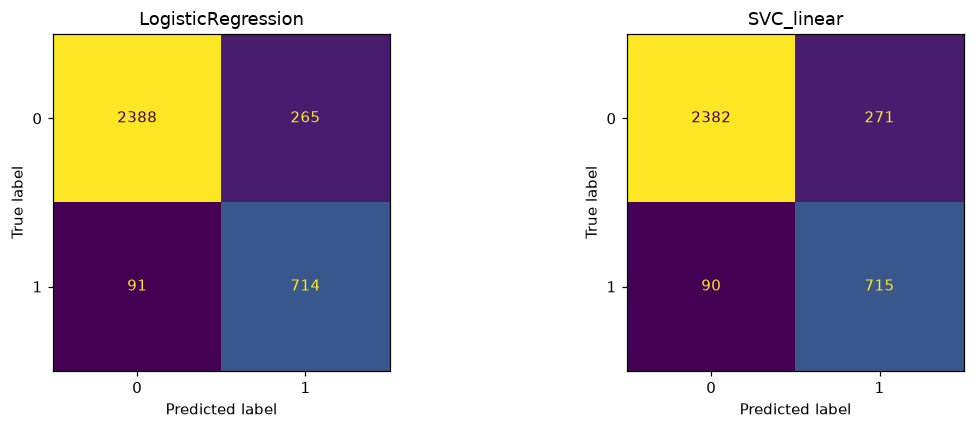

In [3]:
svm_search = fit_search(
    "SVC_linear",
    SVC(
        kernel="linear",
        class_weight="balanced",
        cache_size=512,
        probability=False,
        tol=0.001,
        random_state=SEED,
    ),
)
evaluate("SVC_linear", svm_search.best_estimator_)
metrics = pd.DataFrame(RESULTS).T
display(metrics.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, m) in zip(axes, MODELS.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, m.predict(X_test), ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Вывод.** Для SVC выбрал C=1.0. На test получил balanced accuracy 0.893, F1 0.798 и ROC AUC 0.965. Разница balanced accuracy с LogisticRegression всего -0.0005. На этом разбиении модели работают почти одинаково. Обе строят линейную границу в преобразованных признаках, хотя оптимизируют разные функции потерь. По одному test я бы не выбирал победителя.

<font color='DarkOrange'>**Задание 3 [баллов: 6]:**</font>

1. Многоклассовая классификация. Дайте определения для подходов: микро, макро, взвешенный, пообъктный. Выполните расчёты вручную для слайда 43 (на примере любых 3 промежуточных AUC ROC, поясните, как из промежуточных характеристик получаются 4 финальных). В рамках детализации ОЦИФРУЙТЕ ROC: в Excel, отрисуйте линиями в Word или отрисуйте отдельными отрезками Python-кодом (не используйте готовые функции для ROC).
[баллов: 2]

2. Для одного из кейсов (одного класса) введите три порога бинаризации так, чтоб получились различные accuracy, recall, precision. Вычислите эти метрики вручную и сопроводите визуализацией расчёта для recall и precision (см пример из лекции с окружностями разных цветов и радиусов). По трём парам (precision, recall) постройте эскиз PR-кривой. [баллов: 2]

3. Сделайте выводы по результатам расчётом AUC ROC для многоклассовой классификации (какой вариант лучше, почему, объясните падение AUC ROC при переходе к многоклассовым). [баллов: 1]

4. В каких кейсах/доменах следует применять те или иные варианты? Запишите выводы. [баллов: 1]

### 3.1. Четыре способа усреднить AUC

На слайде задача **multilabel**: у объектов 0 и 1 по два правильных класса. В обычной многоклассовой задаче у каждого объекта только один класс. Это различие нужно для пообъектного усреднения. Значения score на слайде не нормированы по строкам; для независимых меток сумма вероятностей не обязана равняться единице.

- **Macro:** считаю AUC отдельно для каждого столбца «этот класс против остальных», затем беру обычное среднее. Каждый класс имеет одинаковый вес.
- **Weighted:** те же AUC столбцов, но вес класса пропорционален числу его положительных меток. Частые классы влияют сильнее.
- **Micro:** разворачиваю обе матрицы в векторы и строю один ROC по всем парам «объект–класс». Это не среднее трех AUC.
- **Samples:** считаю AUC внутри каждой строки, сравнивая score правильных и неправильных меток объекта. Потом усредняю по объектам. Если в строке только нули или только единицы, AUC строки не определен. В примере таких строк нет.

Вручную AUC можно посчитать как долю правильно упорядоченных пар: положительный score больше отрицательного дает 1, равенство дает 1/2, меньше дает 0. Делим сумму на P·N. Второй способ: выписываем точки ROC при каждом уникальном пороге и складываем площади трапеций. Равные score меняют предсказания одновременно. Оба способа ниже реализованы обычными циклами, без roc_curve, roc_auc_score и готовых интеграторов.

,class 1,class 2,class 3
object,,,
0,1,1,0
1,0,1,1
2,0,1,0
3,1,0,0


,class 1,class 2,class 3
object,,,
0,0.7,0.6,0.5
1,0.3,0.4,0.6
2,0.5,0.9,0.2
3,0.4,0.5,0.1


class 1: 3 побед, 0 равенств; AUC = 3/4


,threshold,TP,FP,FN,TN,FPR,TPR
0,inf,0,0,2,2,0,0
1,0.7,1,0,1,2,0,1/2
2,0.5,1,1,1,1,1/2,1/2
3,0.4,2,1,0,1,1/2,1
4,0.3,2,2,0,0,1,1


class 2: 2 побед, 0 равенств; AUC = 2/3


,threshold,TP,FP,FN,TN,FPR,TPR
0,inf,0,0,3,1,0,0
1,0.9,1,0,2,1,0,1/3
2,0.6,2,0,1,1,0,2/3
3,0.5,2,1,1,0,1,2/3
4,0.4,3,1,0,0,1,1


class 3: 3 побед, 0 равенств; AUC = 1


,threshold,TP,FP,FN,TN,FPR,TPR
0,inf,0,0,1,3,0,0
1,0.6,1,0,0,3,0,1
2,0.5,1,1,0,2,1/3,1
3,0.2,1,2,0,1,2/3,1
4,0.1,1,3,0,0,1,1


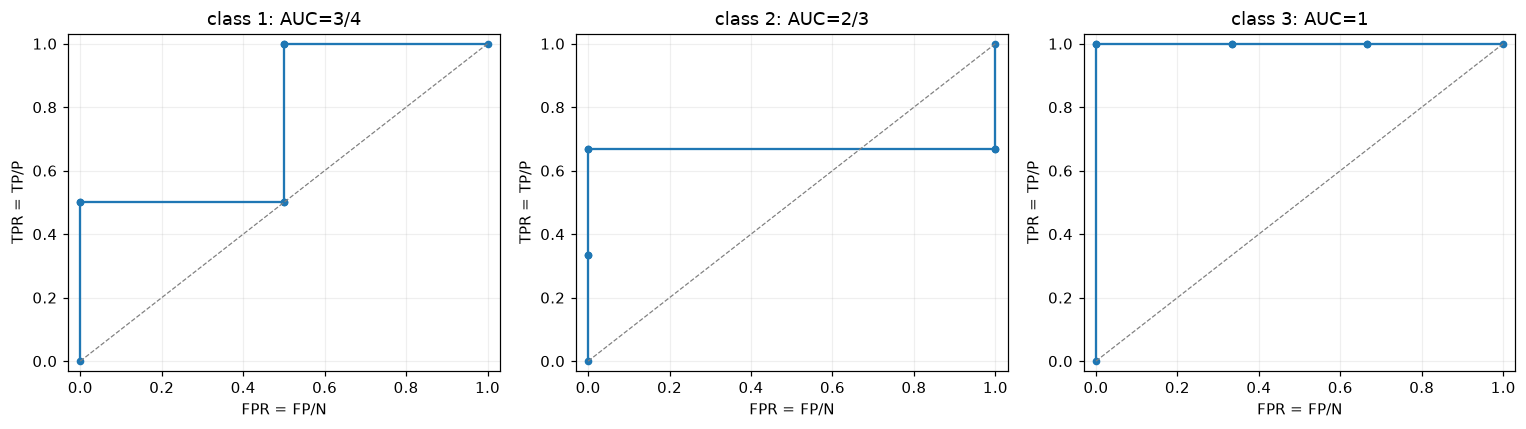

In [4]:
from fractions import Fraction

Y43 = np.array([[1, 1, 0], [0, 1, 1], [0, 1, 0], [1, 0, 0]], dtype=int)
S43 = np.array([[0.7, 0.6, 0.5], [0.3, 0.4, 0.6], [0.5, 0.9, 0.2], [0.4, 0.5, 0.1]])
class_names = ["class 1", "class 2", "class 3"]
display(pd.DataFrame(Y43, columns=class_names).rename_axis("object"))
display(pd.DataFrame(S43, columns=class_names).rename_axis("object"))


def manual_pair_auc(labels, scores):
    pos = [float(s) for y, s in zip(labels, scores) if y == 1]
    neg = [float(s) for y, s in zip(labels, scores) if y == 0]
    if not pos or not neg:
        raise ValueError("AUC requires both positive and negative observations")
    wins = sum((p > n for p in pos for n in neg))
    ties = sum((p == n for p in pos for n in neg))
    return (Fraction(2 * wins + ties, 2 * len(pos) * len(neg)), wins, ties)


def manual_roc(labels, scores):
    labels, scores = (np.asarray(labels), np.asarray(scores))
    P, N = (int(sum(labels)), int(len(labels) - sum(labels)))
    if P == 0 or N == 0:
        raise ValueError("ROC requires both classes")
    rows = []
    for threshold in [float("inf")] + sorted(set(map(float, scores)), reverse=True):
        predicted = scores >= threshold
        tp = int(np.sum(predicted & (labels == 1)))
        fp = int(np.sum(predicted & (labels == 0)))
        rows.append(
            {
                "threshold": threshold,
                "TP": tp,
                "FP": fp,
                "FN": P - tp,
                "TN": N - fp,
                "FPR": Fraction(fp, N),
                "TPR": Fraction(tp, P),
            }
        )
    area = sum(
        (
            (b["FPR"] - a["FPR"]) * (a["TPR"] + b["TPR"]) / 2
            for a, b in zip(rows, rows[1:])
        ),
        Fraction(0),
    )
    return (rows, area)


def plot_segments(ax, points, label):
    for left, right in zip(points, points[1:]):
        ax.plot(
            [float(left["FPR"]), float(right["FPR"])],
            [float(left["TPR"]), float(right["TPR"])],
            color="tab:blue",
            marker="o",
            markersize=4,
        )
    ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=0.8)
    ax.set(
        xlim=(-0.03, 1.03),
        ylim=(-0.03, 1.03),
        xlabel="FPR = FP/N",
        ylabel="TPR = TP/P",
        title=label,
    )
    ax.grid(alpha=0.2)


class_aucs = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for j, name in enumerate(class_names):
    labels, scores = (Y43[:, j], S43[:, j])
    pair_auc, wins, ties = manual_pair_auc(labels, scores)
    points, area = manual_roc(labels, scores)
    class_aucs.append(area)
    print(f"{name}: {wins} побед, {ties} равенств; AUC = {pair_auc}")
    table = pd.DataFrame(points)
    display(table)
    plot_segments(axes[j], points, f"{name}: AUC={area}")
plt.tight_layout()
plt.show()

Для первого класса положительные score равны 0.7 и 0.4, отрицательные 0.3 и 0.5. Первая положительная точка выигрывает обе пары, вторая только одну: AUC₁=(2+1)/4=3/4.

Во втором классе отрицательный объект один, со score 0.5. Положительные 0.6 и 0.9 выше него, а 0.4 ниже: AUC₂=(1+0+1)/3=2/3. В третьем классе положительный score 0.6 выше всех трех отрицательных: AUC₃=3/3=1.

Площади по оцифрованным ROC дают то же самое:

- class 1: (1/2)·(1/2)+(1/2)·1=3/4;
- class 2: 1·(2/3)=2/3;
- class 3: 1·1=1.

Вертикальные отрезки площади не добавляют. Все точки, включая начало (0,0) и конец (1,1), выписаны в таблицах выше.

Четыре оценки считаются так:

**Macro:** (3/4+2/3+1)/3=29/36≈0.805556, на слайде 0.806.

**Weighted:** положительных меток по классам 2, 3 и 1. Получается (2·3/4+3·2/3+1·1)/6=3/4=0.75. Значения p на слайде равны 2/4, 3/4, 1/4; это распространенности классов. Их сумма 1.5, поэтому для весов нужно разделить каждое p на 1.5. Получатся 1/3, 1/2, 1/6.

**Micro:** сравниваю все 6 положительных score со всеми 6 отрицательными. В расчете ниже видны победы и равенства, AUC=5/6≈0.833333.

**Samples:** AUC строк равны 1, 1, 1 и 1/2. В последней строке правильный class 1 имеет score 0.4: выше class 3 со score 0.1, но ниже class 2 со score 0.5. Среднее (1+1+1+1/2)/4=7/8=0.875.

In [5]:
supports = Y43.sum(axis=0)
macro43 = sum(class_aucs, Fraction(0)) / 3
weighted43 = sum((int(n) * a for n, a in zip(supports, class_aucs)), Fraction(0)) / int(
    supports.sum()
)
micro43, wins43, ties43 = manual_pair_auc(Y43.ravel(), S43.ravel())
micro_points, micro_area = manual_roc(Y43.ravel(), S43.ravel())
sample_aucs = [manual_pair_auc(y, s)[0] for y, s in zip(Y43, S43)]
samples43 = sum(sample_aucs, Fraction(0)) / len(Y43)
print(f"Micro: ({wins43} + {ties43}/2) / 36 = {micro43}")
print("Samples:", [str(a) for a in sample_aucs])
averages43 = pd.DataFrame(
    {
        "method": ["macro", "weighted", "micro", "samples"],
        "exact": [str(a) for a in [macro43, weighted43, micro43, samples43]],
        "auc": [float(a) for a in [macro43, weighted43, micro43, samples43]],
        "slide_rounded": [0.806, 0.75, 0.833, 0.875],
    }
)
display(averages43)

Micro: (30 + 0/2) / 36 = 5/6
Samples: ['1', '1', '1', '1/2']


,method,exact,auc,slide_rounded
0,macro,29/36,0.805556,0.806
1,weighted,3/4,0.750000,0.750
2,micro,5/6,0.833333,0.833
3,samples,7/8,0.875000,0.875


### 3.2. Три порога, precision и recall

Для class 2 со слайда взял пороги 0.30, 0.45 и 0.65. Предсказываю 1 при score ≥ порога. Правильные объекты: {0,1,2}, отрицательный: {3}.

- При 0.30 предсказано {0,1,2,3}. TP=3, FP=1, FN=0, TN=0. Accuracy=3/4, recall=3/3=1, precision=3/4.
- При 0.45 предсказано {0,2,3}. TP=2, FP=1, FN=1, TN=0. Accuracy=2/4, recall=2/3, precision=2/3.
- При 0.65 предсказано {2}. TP=1, FP=0, FN=2, TN=1. Accuracy=2/4, recall=1/3, precision=1.

Тройки метрик и все пары (precision, recall) разные. Accuracy у двух порогов совпала: исчез один FP, но появился один FN. На четырех объектах class 2 без пустого предсказанного множества accuracy принимает только 1/2 или 3/4. Поэтому получить здесь три разных accuracy вместе с определенной precision невозможно. С пустым множеством accuracy была бы 1/4, но precision=0/0 не определена; подменять ее нулем ради условия не стал.

Чтобы показать и три разных значения каждой метрики, ниже отдельно разобрал положительный класс квартир из задания 1 на score-порогах −1, 0, 1. Это дополнение к расчету слайда, исходные четыре объекта не меняю. Пороги фиксированы для иллюстрации, лучший порог по test не выбираю.

In [6]:
def manual_threshold_table(labels, scores, thresholds):
    labels, scores = (np.asarray(labels), np.asarray(scores))
    rows = []
    for t in thresholds:
        pred = scores >= t
        tp = int(np.sum(pred & (labels == 1)))
        fp = int(np.sum(pred & (labels == 0)))
        fn = int(np.sum(~pred & (labels == 1)))
        tn = int(np.sum(~pred & (labels == 0)))
        if tp + fp == 0 or tp + fn == 0:
            raise ValueError("Undefined precision or recall")
        rows.append(
            {
                "threshold": t,
                "TP": tp,
                "FP": fp,
                "FN": fn,
                "TN": tn,
                "accuracy": (tp + tn) / len(labels),
                "precision": tp / (tp + fp),
                "recall": tp / (tp + fn),
            }
        )
    return pd.DataFrame(rows)


thresholds43 = [0.3, 0.45, 0.65]
threshold_table43 = manual_threshold_table(Y43[:, 1], S43[:, 1], thresholds43)
display(threshold_table43)
estate_thresholds = manual_threshold_table(
    y_test.to_numpy(),
    MODELS["LogisticRegression"].decision_function(X_test),
    [-1.0, 0.0, 1.0],
)
display(estate_thresholds)
for row in estate_thresholds.itertuples():
    print(
        f"t={row.threshold:g}: accuracy=({row.TP}+{row.TN})/{len(y_test)}={row.accuracy:.6f}; precision={row.TP}/({row.TP}+{row.FP})={row.precision:.6f}; recall={row.TP}/({row.TP}+{row.FN})={row.recall:.6f}"
    )

,threshold,TP,FP,FN,TN,accuracy,precision,recall
0,0.30,3,1,0,0,0.75,0.750000,1.000000
1,0.45,2,1,1,0,0.50,0.666667,0.666667
2,0.65,1,0,2,1,0.50,1.000000,0.333333


,threshold,TP,FP,FN,TN,accuracy,precision,recall
0,-1.0,771,497,34,2156,0.846443,0.608044,0.957764
1,0.0,714,265,91,2388,0.897050,0.729316,0.886957
2,1.0,634,126,171,2527,0.914112,0.834211,0.787578


t=-1: accuracy=(771+2156)/3458=0.846443; precision=771/(771+497)=0.608044; recall=771/(771+34)=0.957764
t=0: accuracy=(714+2388)/3458=0.897050; precision=714/(714+265)=0.729316; recall=714/(714+91)=0.886957
t=1: accuracy=(634+2527)/3458=0.914112; precision=634/(634+126)=0.834211; recall=634/(634+171)=0.787578


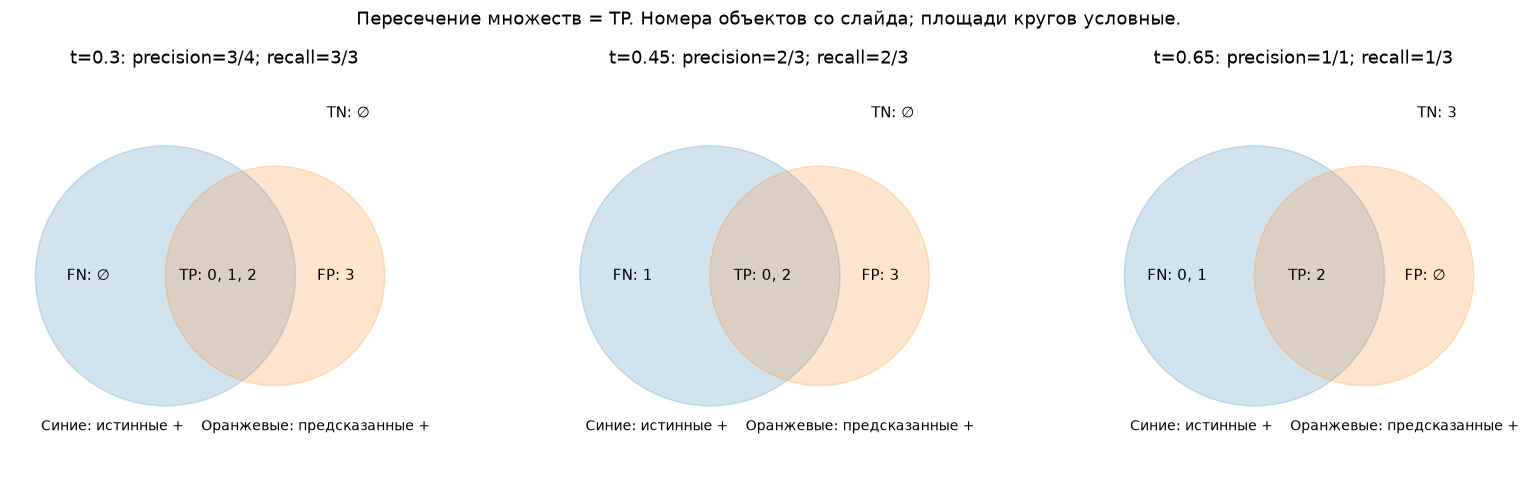

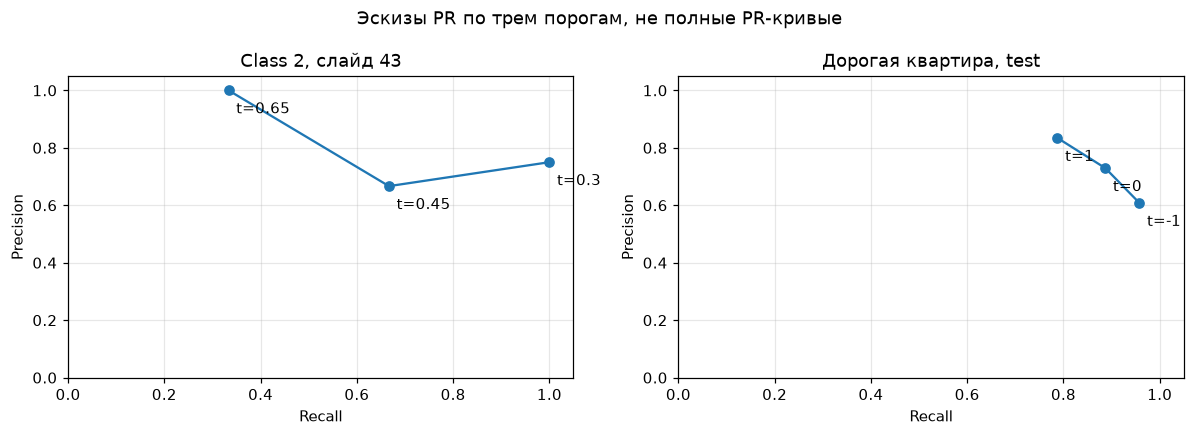

In [7]:
from matplotlib.patches import Circle

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, t in zip(axes, thresholds43):
    positive = set(np.where(Y43[:, 1] == 1)[0])
    predicted = set(np.where(S43[:, 1] >= t)[0])
    groups = {
        "TP": positive & predicted,
        "FN": positive - predicted,
        "FP": predicted - positive,
        "TN": set(range(4)) - (positive | predicted),
    }
    ax.add_patch(Circle((0.38, 0.5), 0.32, color="tab:blue", alpha=0.2))
    ax.add_patch(Circle((0.65, 0.5), 0.27, color="tab:orange", alpha=0.2))
    for key, (x, y) in {
        "FN": (0.19, 0.5),
        "TP": (0.51, 0.5),
        "FP": (0.8, 0.5),
        "TN": (0.83, 0.9),
    }.items():
        ids = ", ".join(map(str, sorted(groups[key]))) or "∅"
        ax.text(x, y, f"{key}: {ids}", ha="center", va="center", fontsize=10)
    row = threshold_table43.loc[threshold_table43.threshold == t].iloc[0]
    ax.text(0.25, 0.12, "Синие: истинные +", ha="center", fontsize=9)
    ax.text(0.75, 0.12, "Оранжевые: предсказанные +", ha="center", fontsize=9)
    ax.set_title(
        f"t={t}: precision={int(row.TP)}/{int(row.TP + row.FP)}; recall={int(row.TP)}/{int(row.TP + row.FN)}"
    )
    ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal")
    ax.axis("off")
fig.suptitle(
    "Пересечение множеств = TP. Номера объектов со слайда; площади кругов условные."
)
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, table, title in [
    (axes[0], threshold_table43, "Class 2, слайд 43"),
    (axes[1], estate_thresholds, "Дорогая квартира, test"),
]:
    ordered = table.sort_values("recall")
    ax.plot(ordered.recall, ordered.precision, "o-")
    for row in ordered.itertuples():
        ax.annotate(
            f"t={row.threshold:g}",
            (row.recall, row.precision),
            xytext=(5, -15),
            textcoords="offset points",
        )
    ax.set(
        xlabel="Recall", ylabel="Precision", title=title, xlim=(0, 1.05), ylim=(0, 1.05)
    )
    ax.grid(alpha=0.3)
plt.suptitle("Эскизы PR по трем порогам, не полные PR-кривые")
plt.tight_layout()
plt.show()

Синий круг содержит реальные положительные объекты, оранжевый предсказанные. Пересечение нужно в числителе обеих метрик. Для recall делю его размер на число объектов в синем круге, для precision на число объектов в оранжевом.

При увеличении порога recall не растет: положительных предсказаний становится меньше. Precision не обязана монотонно расти. В примере сначала она падает с 3/4 до 2/3: теряется правильный объект 1, а неправильный 3 еще остается. При следующем пороге ложных срабатываний уже нет и precision равна 1. Линии на PR-графике соединяют только три рассчитанные точки, площадь по ним не выдаю за AP.

### 3.3. Что показали четыре AUC

На слайде samples=0.875 больше остальных, но это не делает способ усреднения лучшим. Он отвечает на другой вопрос: насколько правильно ранжируются метки одного объекта. Для трех объектов ранжирование идеальное, для четвертого правильная метка обгоняет одну из двух неправильных.

Macro=0.806 учитывает все классы поровну. Weighted=0.75 ниже, потому что самый частый class 2 имеет самый низкий AUC=2/3 и получает половину веса. Для оценки редких классов я бы смотрел macro вместе с отдельными AUC, а не только weighted.

Micro=0.833 сравнивает в том числе score из разных столбцов. Поэтому ему нужна сопоставимость шкал между классами. Это не взвешенное среднее столбцов; даже монотонное преобразование score одного класса может изменить micro, не меняя AUC этого класса.

Обязательного падения AUC при переходе к нескольким классам нет. Здесь относительно идеального class 3 усреднение снижает оценку: в остальных классах есть ошибки ранжирования. Но относительно class 1 с AUC=0.75 macro, micro и samples, наоборот, выше. На другой задаче падение может быть связано с более похожими классами, изменением отрицательного класса в one-vs-rest или малым числом примеров. Сравнивать это с ROC AUC≈0.965 квартир из заданий 1–2 как эффект числа классов нельзя: данные и целевая переменная разные.

### 3.4. Где какое усреднение использовать

| Подход | Пример применения | Что проверять вместе с ним |
|---|---|---|
| Macro | Классификация редких дефектов, когда каждый тип одинаково важен | AUC и размер выборки каждого класса: у редких оценка менее устойчива |
| Weighted | Поток обращений с устойчивой частотой тем, когда важно качество на типичном составе потока | Не скрывает ли частая тема плохое распознавание редкой; веса отражают частоту, не стоимость ошибки |
| Micro | Общий список пар «документ–тег», который сортируется одним score | Сопоставимость score разных тегов; частые метки могут доминировать |
| Samples | Ранжирование подходящих тегов отдельно для каждого документа или товара | В каждой строке нужны и положительные, и отрицательные метки |

Если ошибки классов стоят по-разному, ни одно стандартное усреднение само по себе стоимость не учитывает. Тогда нужны отдельные метрики и явно заданные веса ошибок. Для решения о срабатывании после AUC все равно нужен порог и расчет precision/recall.

<font color='DarkOrange'>**Задание 4 [баллов: 2]:**</font>

Исследуйте вопрос выбросов/новизны для данных в вашем датасете с использованием OneClassSVM (дайте краткую теоретическую характеристику, используйте готовые решения для получения результатов, сделайте выводы)

Материалы:
1) https://scikit-learn.ru/stable/modules/outlier_detection.html,
2) https://alexanderdyakonov.wordpress.com/, Поиск аномалий

### Какие объявления считаю необычными

Для поиска аномалий взял OneClassSVM с RBF-ядром. Он строит нелинейную область типичных сочетаний признаков. Внутри predict возвращает +1, снаружи −1. Отрицательный decision_function означает кандидата в аномалии.

Здесь использую цену, площадь, санузлы, год и парковку. Цену и площадь логарифмирую. Это отдельная задача без учителя, поэтому цена здесь допустима. В классификаторы выше она не попадает.

Город и округ не включал, чтобы редкая категория сама по себе не определяла расстояние. Но у такого решения есть ограничение: местную норму цены модель не знает. Пропуски и масштабирование считаю только по train.

Проверил nu=0.01, 0.05 и 0.10. Параметр ограничивает долю ошибок на train сверху и долю опорных векторов снизу, с учетом численной точности. На test доля аномалий не обязана совпадать с nu. Gamma=scale задает масштаб RBF по размерности и дисперсии входа.

Для подробного разбора заранее выбрал nu=0.05. Остальные значения нужны, чтобы посмотреть чувствительность. На train ищу выбросы, на test проверяю необычность новых объектов. Чистой выборки нормы у меня нет, поэтому строгим novelty detection это назвать нельзя. Разметки аномалий тоже нет, precision и recall детектора посчитать не получится.

,nu,train_outlier_share,test_outlier_share,support_share
0,0.01,0.010411,0.013013,0.013664
1,0.05,0.050174,0.054367,0.051403
2,0.10,0.099769,0.096298,0.100925


,Price,LivingArea,NumberOfBathrooms,ConstructionYear,Parking,District,City,score,outlier
178642,1395000.0,263.0,10.0,2016.0,0.0,Leiria,Leiria,-48.005654,True
152750,2350000.0,377.0,8.0,2010.0,1.0,Lisboa,Lisboa,-42.233266,True
152935,270000.0,244.0,6.0,1951.0,0.0,Lisboa,Lisboa,-40.213449,True
154765,5125000.0,396.0,7.0,2026.0,0.0,Lisboa,Cascais,-37.192580,True
154714,5400000.0,328.0,7.0,2026.0,0.0,Lisboa,Cascais,-36.625196,True
145098,16000.0,120.0,2.0,1985.0,0.0,Faro,Albufeira,-35.724268,True
137801,468000.0,672.0,3.0,1995.0,0.0,Braga,Braga,-34.983640,True
153473,2200000.0,265.0,3.0,1913.0,0.0,Lisboa,Lisboa,-34.266604,True
144281,15900.0,45.0,1.0,1990.0,1.0,Faro,Albufeira,-33.631499,True
150541,695000.0,90.0,1.0,1900.0,1.0,Lisboa,Lisboa,-33.499311,True


,Price,LivingArea,NumberOfBathrooms,ConstructionYear,Parking
outlier,,,,,
False,339000.0,89.0,2.0,2001.0,0.0
True,437500.0,95.0,2.0,1996.0,0.0


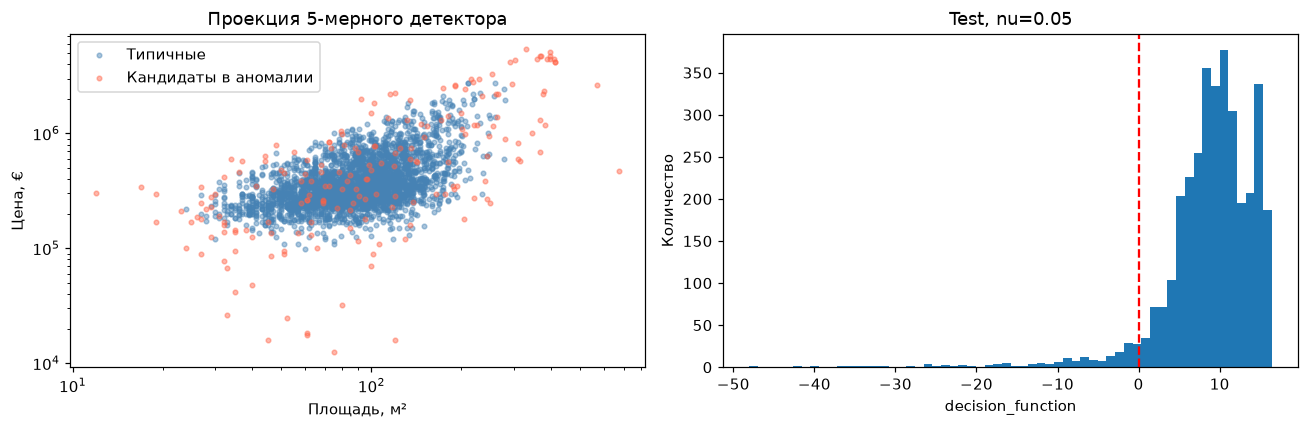

In [8]:
ANOM = ["Price", "LivingArea", "NumberOfBathrooms", "ConstructionYear", "Parking"]


def log_price_area(a):
    a = np.array(a, dtype=float, copy=True)
    a[:, :2] = np.log(a[:, :2])
    return a


A_train, A_test = (df.loc[train_idx, ANOM], df.loc[test_idx, ANOM])
anom_prep = Pipeline(
    [
        ("impute", SimpleImputer(strategy="median")),
        ("log", FunctionTransformer(log_price_area)),
        ("scale", StandardScaler()),
    ]
)
Z_train = anom_prep.fit_transform(A_train)
Z_test = anom_prep.transform(A_test)
anom_models, rows = ({}, [])
for nu in [0.01, 0.05, 0.1]:
    detector = OneClassSVM(kernel="rbf", gamma="scale", nu=nu, cache_size=512).fit(
        Z_train
    )
    anom_models[nu] = detector
    rows.append(
        {
            "nu": nu,
            "train_outlier_share": (detector.predict(Z_train) == -1).mean(),
            "test_outlier_share": (detector.predict(Z_test) == -1).mean(),
            "support_share": len(detector.support_) / len(Z_train),
        }
    )
sensitivity = pd.DataFrame(rows)
display(sensitivity)
detector = anom_models[0.05]
anomalies = df.loc[test_idx, ANOM + ["District", "City"]].copy()
anomalies["score"] = detector.decision_function(Z_test)
anomalies["outlier"] = detector.predict(Z_test) == -1
display(anomalies.nsmallest(10, "score"))
display(anomalies.groupby("outlier")[ANOM].median())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for flag, color, label in [
    (False, "steelblue", "Типичные"),
    (True, "tomato", "Кандидаты в аномалии"),
]:
    sub = anomalies[anomalies.outlier == flag]
    axes[0].scatter(sub.LivingArea, sub.Price, s=9, alpha=0.45, c=color, label=label)
axes[0].set(
    xscale="log",
    yscale="log",
    xlabel="Площадь, м²",
    ylabel="Цена, €",
    title="Проекция 5-мерного детектора",
)
axes[0].legend()
axes[1].hist(anomalies.score, bins=60)
axes[1].axvline(0, color="red", ls="--")
axes[1].set(xlabel="decision_function", ylabel="Количество", title="Test, nu=0.05")
plt.tight_layout()
plt.show()

**Вывод.** При nu=0.05 модель отметила 188 из 3458 объявлений на test, это 5.4%. Самый необычный объект: 1,395,000 €, 263 м², санузлов 10, год 2016, парковок 0, город Leiria. Я бы начал проверку с этого объявления. Редкое сочетание еще не означает ошибку в данных. На графике показаны только цена и площадь, а детектор смотрит на пять признаков, поэтому часть отмеченных точек визуально выглядит обычной. По таблице с разными nu видно, насколько меняется доля кандидатов. Выбрать лучший nu без разметки не могу. Удалять эти строки из классификации не стал: дорогие квартиры как раз нужно находить. Для дальнейшей проверки нужны исходные объявления и региональные цены.

### Источники

- [Датасет Kaggle](https://www.kaggle.com/datasets/luvathoms/portugal-real-estate-2024).
- [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
- [SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html).
- [Поиск выбросов и новизны](https://scikit-learn.org/stable/modules/outlier_detection.html).